## Fibroblast single-cell and multiome integration

In [1]:
import sys 
import os
from datetime import datetime

import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import hdf5plugin

import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Add repo path to sys path (allows to access scripts and metadata from repo)
repo_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment'
sys.path.insert(1, repo_path) 
sys.path.insert(2, '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts')

import torch
torch.cuda.is_available()

%reload_ext autoreload
%autoreload 2

import scvi 
from scvi_wrapper2 import run_scvi

/nfs/team205/vk8/mambaforge/envs/scvi-env3/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'param_categorical_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/nfs/team205/vk8/mambaforge/envs/scvi-env3/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'param_continuous_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


In [3]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all" # to show output from all the lines in a cells
pd.set_option('display.max_column',None) # display all the columns in pandas
pd.options.display.max_rows = 100
import matplotlib
from matplotlib import rcParams
rcParams['pdf.fonttype'] = 42
sc.settings.set_figure_params(dpi = 150, color_map = 'RdPu', dpi_save = 150, vector_friendly = True, format = 'pdf')

In [4]:
sc.settings.set_figure_params(dpi = 100, color_map = 'RdPu', dpi_save = 150, vector_friendly = True, format = 'pdf')

In [5]:
# Define plot and path dirs
plot_path = os.path.join(repo_path, 'plots')
data_path = os.path.join(repo_path, 'data')
model_path = os.path.join(repo_path, 'models')
general_data_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/data'

## Load adata

In [6]:
adata_scell = ad.read_h5ad(f'{general_data_path}/objects/rna/thyAgeing_all_scvi_v6_2026-05-01.zarr')

In [7]:
anno = pd.read_csv(f'{general_data_path}/objects/rna/thyAgeing_all_scvi_v5_2025-10-15_curatedAnno_v11.csv', index_col=0)
anno_cols = ['taa_l0', 'taa_l1', 'taa_l2', 'taa_l2_v2', 'taa_l3', 'taa_l3_v2', 'taa_l4', 'taa_l5']
adata_scell.obs = adata_scell.obs.drop(columns=[c for c in anno_cols if c in adata_scell.obs.columns]).join(anno[anno_cols])
adata_fb_scell = adata_scell[adata_scell.obs['taa_l1']=='Fb',].copy()      # keep stroma only
adata_fb_scell = adata_fb_scell[adata_fb_scell.obs['taa_l1'].notna()].copy()

In [8]:
del adata_scell
import gc
gc.collect()

3535

In [9]:
adata_fbs_scell = ad.read_h5ad('/nfs/team205/vk8/projects/thymus_ageing_atlas/cellxgene/ThyAge_Fb_compartment_2025-10-23.zarr')

In [10]:
# The multiome object was written with anndata >= 0.12, where `None` has its own on-disk
# encoding ('null'). anndata 0.11.4 (this env) has no reader registered for it, so the read
# dies on uns/dendrogram_*/use_rep with an IORegistryError. Registering that one reader is
# enough - scan_encodings lists every encoding in the file and flags unreadable ones.
from anndata_compat import patch_null_io, scan_encodings, read_h5ad_light

multiome_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/Nuclei_multiome/adata_scenic_scvi_v3_anno_v3_globa_counts_added.h5ad'
patch_null_io()
scan_encodings(multiome_path)

anndata 0.11.4: registered a reader for the "null" spec


True

ok   array                0.2.0    n=191   e.g. obs/DevThy_pred/codes
ok   categorical          0.2.0    n=87    e.g. obs/DevThy_pred
ok   csr_matrix           0.1.0    n=5     e.g. X
ok   dataframe            0.2.0    n=2     e.g. obs
ok   dict                 0.1.0    n=50    e.g. layers
ok   null                 0.1.0    n=9     e.g. uns/dendrogram_celltype_L1/use_rep
ok   nullable-boolean     0.1.0    n=2     e.g. obs/cite
ok   numeric-scalar       0.2.0    n=38    e.g. uns/leiden_split_12/params/n_iterations
ok   rec-array            0.2.0    n=5     e.g. uns/rank_genes_groups/logfoldchanges
ok   string               0.2.0    n=25    e.g. uns/dendrogram_celltype_L1/cor_method
ok   string-array         0.2.0    n=152   e.g. obs/DevThy_pred/categories


{('csr_matrix', '0.1.0'): ['X',
  'layers/counts',
  'layers/counts_old_suspect',
  'obsp/connectivities',
  'obsp/distances'],
 ('dict', '0.1.0'): ['layers',
  'obsm',
  'obsp',
  'uns',
  'uns/dendrogram_celltype_L1',
  'uns/dendrogram_celltype_L1/dendrogram_info',
  'uns/dendrogram_celltype_L3',
  'uns/dendrogram_celltype_L3/dendrogram_info',
  'uns/dendrogram_celltype_v2_L3',
  'uns/dendrogram_celltype_v2_L3/dendrogram_info',
  'uns/dendrogram_leiden_split_16',
  'uns/dendrogram_leiden_split_16/dendrogram_info',
  'uns/dendrogram_prelim_cell_type_L1',
  'uns/dendrogram_prelim_cell_type_L1/dendrogram_info',
  'uns/dendrogram_prelim_cell_type_L3',
  'uns/dendrogram_prelim_cell_type_L3/dendrogram_info',
  'uns/dendrogram_scVI_v1_leiden_2',
  'uns/dendrogram_scVI_v1_leiden_2/dendrogram_info',
  'uns/dendrogram_scVI_v2_leiden_1.8',
  'uns/dendrogram_scVI_v2_leiden_1.8/dendrogram_info',
  'uns/leiden_split_12',
  'uns/leiden_split_12/params',
  'uns/leiden_split_16',
  'uns/leiden_split_

In [11]:
adata_multiome = read_h5ad_light(multiome_path, X=True, layers=['counts'],
                                  obsm=['X_scVI_v3', 'X_umap'], uns=True)

  read layers/counts
  read obsm/X_scVI_v3
  read obsm/X_umap
AnnData object with n_obs × n_vars = 119597 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'scrublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'library', 'donor', 'chemistry_detail', 'sort', 'type', 'health_status', 'sort_type', 'age_group', 'age_group3', 'age', 'age_num', 'study', 'sex', 'age_months', 'tissue_site', 'log_total_counts', 'log_n_genes', 'pre_filter_clusters', 'DevThy_pred',

In [12]:
adata_multiome.X = adata_multiome.layers['counts'].copy()
adata_fb_multi = adata_multiome[adata_multiome.obs['global_scenic_lab']=='FB',].copy()

In [13]:
del adata_multiome
gc.collect()

3913

In [14]:
adata_fb_all = ad.concat([adata_fb_scell, adata_fb_multi], merge = 'unique', label = 'batch', keys = ['scell', 'multiome'])

In [15]:
cols2add_r = [col for col in adata_fb_multi.obs.columns.tolist() if col not in adata_fb_all.obs.columns]
adata_fb_all.obs = adata_fb_all.obs.merge(adata_fb_multi.obs[cols2add_r], how = 'left', left_index = True, right_index = True)
cols2add_l = [col for col in adata_fb_scell.obs.columns.tolist() if col not in adata_fb_all.obs.columns]
adata_fb_all.obs = adata_fb_all.obs.merge(adata_fb_scell.obs[cols2add_l], how = 'left', left_index = True, right_index = True)

In [16]:
from utils_vk8 import regen_embed, ctypist_anno, run_leiden, remove_small_samples
from scvi_wrapper2 import run_scvi

In [18]:
adata_fb_all.obs['age_group'].value_counts()

age_group
adult          71354
infant          6423
aged            5373
paed            1526
pooled           529
paed(early)       84
Name: count, dtype: int64

In [20]:
adata_fb_all.obs['chemistry_simple'] = adata_fb_all.obs['chemistry_simple'].astype(str)

In [21]:
adata_fb_all.obs.loc[adata_fb_all.obs['chemistry_detail'] == 'multiomeGEX', 'chemistry_simple'] = 'multiome3GEX'

In [33]:
adata_fb_all.obs['donor_comb'] = adata_fb_all.obs['donor_dmux'].astype(str).copy()
adata_fb_all.obs.loc[adata_fb_all.obs['donor_comb'].isna(),'donor_comb'] = adata_fb_all.obs.loc[adata_fb_all.obs['donor_comb'].isna(),'donor']

In [35]:
adata_fb_all.obs.loc[adata_fb_all.obs['donor_comb']=='nan','donor_comb'] = adata_fb_all.obs.loc[adata_fb_all.obs['donor_comb']=='nan','donor']

In [23]:
adata_fb_all.obs.loc[adata_fb_all.obs['donor']=='pooled']

,barcode,library,index,library_tcr_ab,library_tcr_gd,library_bcr,path_raw_gex,starsolo_version,path_cellbender_gex,path_cellranger_arc,donor,chemistry_simple,chemistry_detail,chemistry_orig,origin_institute,research_no,study,sort,sort_type,in_HTSA,public_data,type,cite,health_status,age_group,age_group2,age,age_num,age_unit,age_cont,sex,age_months,path_tcr_ab,path_tcr_gd,path_bcr,scrublet_score,predicted_doublet,batch,sample_barcode,gex_barcode,atac_barcode,cellranger_gex_umis_count,cellranger_gex_genes_count,snap_atac_fragments,snap_TSS_enrichment,f_intronic,cellranger_is_cell,EDM_is_cell,multiQC_leiden,multiQC_is_cell,atac_doublet_score,sample_ID,n_genes_by_counts,total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,total_counts_hb,pct_counts_hb,amulet_pval,amulet_qval,age_group3,tissue_site,log_total_counts,log_n_genes,pre_filter_clusters,DevThy_pred,DevThy_prob,chrY_exp,XIST_exp,min_filter_clusters,ThyAgeing_L1_pred,ThyAgeing_L1_prob,prelim_cell_type_L1,ThyAgeing_L3_pred,ThyAgeing_L3_prob,prelim_cell_type_L3,donor_age,ThyAgeing_L4_pred,ThyAgeing_L4_prob,donor_dmux,status,assignment,log_prob_singleton,log_prob_doublet,cluster0,cluster1,cluster2,pool,predicted_doublet2,snuc_prelim_clusters,age_group_dmux,age_group3_dmux,age_dmux,age_num_dmux,age_unit_dmux,age_cont_dmux,sex_dmux,age_months_dmux,scVI_v1_leiden_1.6,scVI_v1_leiden_2,chemistry_celltype,celltype_v1_L1,celltype_v1_L3,leiden_split_12,leiden_split_16,leiden_split_TEC,leiden_split_FB,leiden_split_22,amulet_doublet,age_chem_sample,flag_scrublet_gex,flag_scrublet_atac,multiome_doublet_flag,snuc_doublet_flag,amulet_flag,n_flags,fragment_tss_status,atac_qc_pass,any_high_conf,scVI_v2_leiden_2,scVI_v2_leiden_1.8,celltype_v2_L1,celltype_v2_L3,celltype_v3_L3,celltype_v3_L2,age_scenic,scenic_label,global_scenic_lab,TEC_FB_scenic_label,scVI_v3_leiden_2,sample,comment,n_counts,n_genes,percent_mito,percent_ribo,percent_hb,anno_status,qc_status,taa_l0,taa_l1,taa_l2,taa_l2_v2,taa_l3,taa_l3_v2,taa_l4,taa_l5


In [74]:
adata_fb_all.obs['type'].value_counts()

type
cells     70258
nuclei    15031
Name: count, dtype: int64

### Harmonise cross-assay QC covariates (this is what broke scVI below)

`ad.concat(..., join='inner')` keeps only the `obs` columns present in **both** objects, so every
column re-added by the two left-merges above is `NaN` in the assay it did not come from
(`percent_mito`/`n_counts`/`n_genes` for the 15,031 nuclei; `pct_counts_mt`/`total_counts`/
`n_genes_by_counts` for the 70,258 cells).

`run_scvi` defaults to `cont_cov_scvi=['percent_mito']` and the call below never overrode it, so
scVI received a continuous covariate that is `NaN` for every nucleus. `scvi-tools` does not
validate its inputs, so the `NaN` went straight into the encoder and the whole latent came out
`NaN` on the very first minibatch.

In [37]:
# Assay-agnostic QC covariates. Mind the scales: percent_* are FRACTIONS (0-0.15) while
# pct_counts_* are PERCENT (0-20) - hence the x100, after which both assays sit at ~3% median.
o = adata_fb_all.obs
o['pct_mito'] = (o['percent_mito'].astype(float) * 100).fillna(o['pct_counts_mt'].astype(float))
o['pct_ribo'] = (o['percent_ribo'].astype(float) * 100).fillna(o['pct_counts_ribo'].astype(float))
o['qc_n_counts'] = o['n_counts'].astype(float).fillna(o['total_counts'].astype(float))
o['qc_n_genes'] = o['n_genes'].astype(float).fillna(o['n_genes_by_counts'].astype(float))


o[['pct_mito', 'pct_ribo', 'qc_n_counts', 'qc_n_genes', 'scrublet_score']].isna().sum()
o.groupby('type', observed=True)[['pct_mito', 'pct_ribo', 'qc_n_counts', 'qc_n_genes']].median()
pd.crosstab(o['type'], o['chemistry_simple'])

pct_mito          0
pct_ribo          0
qc_n_counts       0
qc_n_genes        0
scrublet_score    0
dtype: int64

,pct_mito,pct_ribo,qc_n_counts,qc_n_genes
type,,,,
cells,3.580319,15.532625,5032.0,1756.0
nuclei,8.830972,2.236909,3648.0,1631.0


chemistry_simple,3GEX,5GEX,multiome3GEX
type,,,
cells,7404,62854,0
nuclei,613,0,14418


In [38]:
# --- Pre-flight guard: everything scVI will see must be finite ------------------------
import scipy.sparse as sp

LAYER_RAW  = 'X'                    # X holds the raw counts; layers['counts'] is deleted below
BATCH_SCVI = 'type'
CAT_COVS   = ['donor', 'chemistry_simple']
CONT_COVS  = ['pct_mito']           # or None to drop continuous covariates entirely

def check_scvi_inputs(adata, layer='X', batch=None, cat_covs=(), cont_covs=None):
    """Print anything that would make scVI emit NaN: non-finite or negative counts, cells with
    an empty library, NaN/inf continuous covariates, NaN or singleton categorical levels."""
    X = adata.X if layer == 'X' else adata.layers[layer]
    d = X.data if sp.issparse(X) else np.asarray(X).ravel()
    print(f'{layer:<7} dtype={d.dtype} min={d.min():g} max={d.max():g} '
          f'n_nan={int(np.isnan(d).sum())} n_neg={int((d < 0).sum())} '
          f'integer_valued={bool(np.all(d == np.rint(d)))}')
    lib = np.asarray(X.sum(1)).ravel()
    print(f'{"libsize":<7} min={lib.min():g} n_cells_with_zero_counts={int((lib == 0).sum())}')
    for c in [batch] + list(cat_covs):
        if c is None:
            continue
        vc = adata.obs[c].astype(str).value_counts()
        print(f'cat   {c:<17} n_levels={vc.size:<4} n_NaN={int(adata.obs[c].isna().sum()):<6} '
              f'smallest_level={vc.min()} ({vc.idxmin()})')
    for c in (cont_covs or []):
        v = pd.to_numeric(adata.obs[c], errors='coerce').to_numpy(dtype=float)
        print(f'cont  {c:<17} n_NaN={int(np.isnan(v).sum()):<6} n_inf={int(np.isinf(v).sum()):<4} '
              f'min={np.nanmin(v):.4g} max={np.nanmax(v):.4g}')
    if batch is not None:
        for c in cat_covs:
            ct = pd.crosstab(adata.obs[batch], adata.obs[c])
            print(f'shared {c:<16} {int(((ct > 0).sum(0) > 1).sum())}/{ct.shape[1]} '
                  f'levels seen in more than one "{batch}"')

check_scvi_inputs(adata_fb_all, LAYER_RAW, BATCH_SCVI, CAT_COVS, CONT_COVS)

X       dtype=float64 min=1 max=6937 n_nan=0 n_neg=0 integer_valued=True
libsize min=455 n_cells_with_zero_counts=0
cat   type              n_levels=2    n_NaN=0      smallest_level=15031 (nuclei)
cat   donor             n_levels=52   n_NaN=0      smallest_level=4 (Thy9)
cat   chemistry_simple  n_levels=3    n_NaN=0      smallest_level=8017 (3GEX)
cont  pct_mito          n_NaN=0      n_inf=0    min=0 max=20
shared donor            6/52 levels seen in more than one "type"
shared chemistry_simple 1/3 levels seen in more than one "type"


In [40]:
adata_fb_all.layers['counts'] = adata_fb_all.X.copy()

In [43]:
# --- Check obs/var dtypes before committing to a multi-GB write -----------------------
# `ad.concat` and `obs.merge` both fall back to object dtype whenever the two objects
# disagree, and anndata can only write an object column if every non-null element is a
# string. Here that hits at least three columns: `cite` (categorical in the scRNAseq object
# vs nullable-boolean in the multiome), `predicted_doublet` (bool vs categorical) and
# `any_high_conf` (multiome-only bool -> bool + NaN after the left-merge). Each raises
# "TypeError: Can't implicitly convert non-string objects to strings" - and only after X has
# already been written. audit_dtypes names them, sanitize_for_write coerces them (bool+NaN ->
# nullable 'boolean', genuinely mixed -> string categorical), and dry_run_write replays the
# real writer on obs/var/uns/obsm alone, so a mistake costs seconds not the whole write.
from anndata_compat import audit_dtypes, sanitize_for_write, dry_run_write

audit_dtypes(adata_fb_all)
sanitize_for_write(adata_fb_all, inplace=True)
dry_run_write(adata_fb_all)

3 entrie(s) will make write_h5ad fail - sanitize_for_write() fixes them:
where               key  dtype  n_missing verdict                                     reason                   fix
  obs              cite object      15138    FAIL      mixed element types (['bool', 'str']) -> string categorical
  obs predicted_doublet object          0    FAIL numbers stored as object (['bool', 'int'])            -> numeric
  obs     any_high_conf object      70258    FAIL                  bool + missing (['bool']) -> nullable 'boolean'


,where,key,dtype,n_missing,verdict,reason,fix
0,obs,cite,object,15138,FAIL,"mixed element types (['bool', 'str'])",-> string categorical
1,obs,predicted_doublet,object,0,FAIL,"numbers stored as object (['bool', 'int'])",-> numeric
2,obs,any_high_conf,object,70258,FAIL,bool + missing (['bool']),-> nullable 'boolean'


sanitize_for_write: 3 entrie(s) coerced
  obs['cite']: object (mixed element types (['bool', 'str'])) -> category
  obs['predicted_doublet']: object (numbers stored as object (['bool', 'int'])) -> int64
  obs['any_high_conf']: object (bool + missing (['bool'])) -> boolean


AnnData object with n_obs × n_vars = 85289 × 35530
    obs: 'barcode', 'library', 'index', 'library_tcr_ab', 'library_tcr_gd', 'library_bcr', 'path_raw_gex', 'starsolo_version', 'path_cellbender_gex', 'path_cellranger_arc', 'donor', 'chemistry_simple', 'chemistry_detail', 'chemistry_orig', 'origin_institute', 'research_no', 'study', 'sort', 'sort_type', 'in_HTSA', 'public_data', 'type', 'cite', 'health_status', 'age_group', 'age_group2', 'age', 'age_num', 'age_unit', 'age_cont', 'sex', 'age_months', 'path_tcr_ab', 'path_tcr_gd', 'path_bcr', 'scrublet_score', 'predicted_doublet', 'batch', 'sample_barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes',

dry run wrote obs/var/uns/obsm ok (66.1 MB; temporary file, removed)


True

In [44]:
adata_fb_all

AnnData object with n_obs × n_vars = 85289 × 35530
    obs: 'barcode', 'library', 'index', 'library_tcr_ab', 'library_tcr_gd', 'library_bcr', 'path_raw_gex', 'starsolo_version', 'path_cellbender_gex', 'path_cellranger_arc', 'donor', 'chemistry_simple', 'chemistry_detail', 'chemistry_orig', 'origin_institute', 'research_no', 'study', 'sort', 'sort_type', 'in_HTSA', 'public_data', 'type', 'cite', 'health_status', 'age_group', 'age_group2', 'age', 'age_num', 'age_unit', 'age_cont', 'sex', 'age_months', 'path_tcr_ab', 'path_tcr_gd', 'path_bcr', 'scrublet_score', 'predicted_doublet', 'batch', 'sample_barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes',

In [45]:
today = datetime.now().strftime("%Y-%m-%d")
adata_fb_all.write_h5ad(
        f'{data_path}/objects/thyAgeing_Fb_scell_multiome_nuclei_{today}.zarr',
        compression=hdf5plugin.FILTERS["zstd"],
        compression_opts=hdf5plugin.Zstd(clevel=5).filter_options,
    )

Removed excluded genes
Highly variable genes selected in total (85289, 10000)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/nfs/team205/vk8/mambaforge/envs/scvi-env3/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=5` in the `DataLoader` to improve performance.
/nfs/team205/vk8/mambaforge/envs/scvi-env3/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=5` in the `DataLoader` to improve performance.


Training:   0%|          | 0/400 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=400` reached.


scVI model trained
UMAP performed


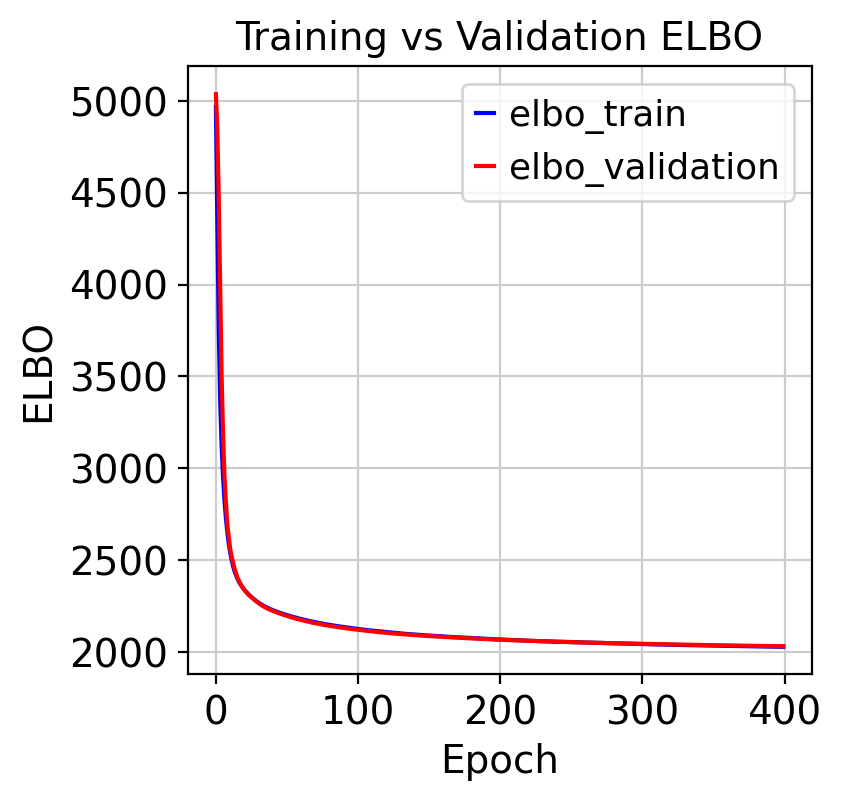

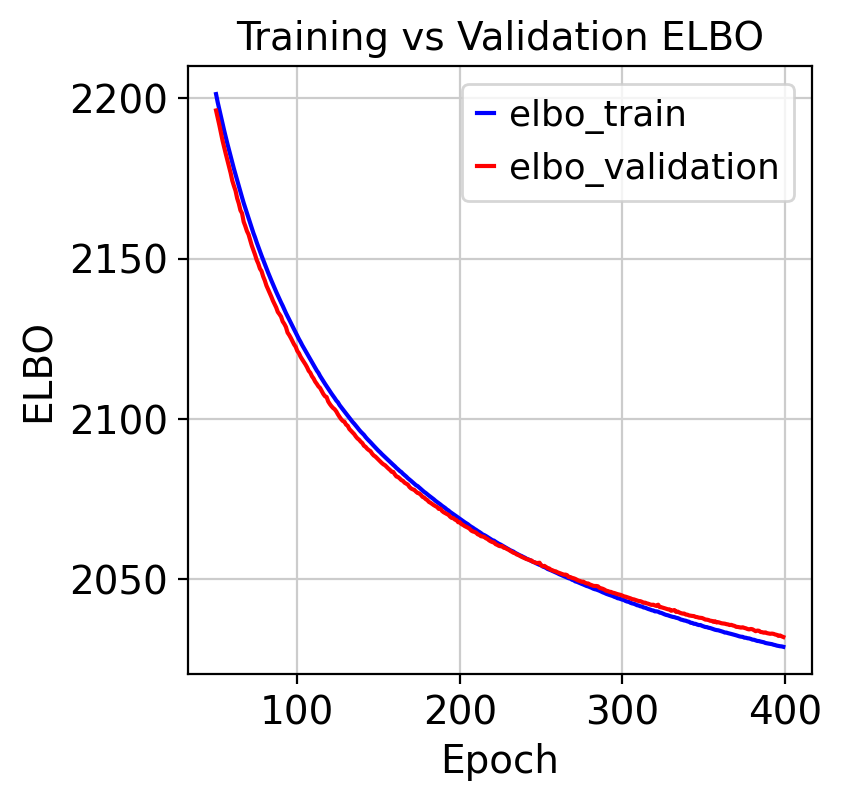

Plotting doublet_metric
Plotting age
Plotting batch_mixing
Plotting cat_covs
Plotting cont_covs


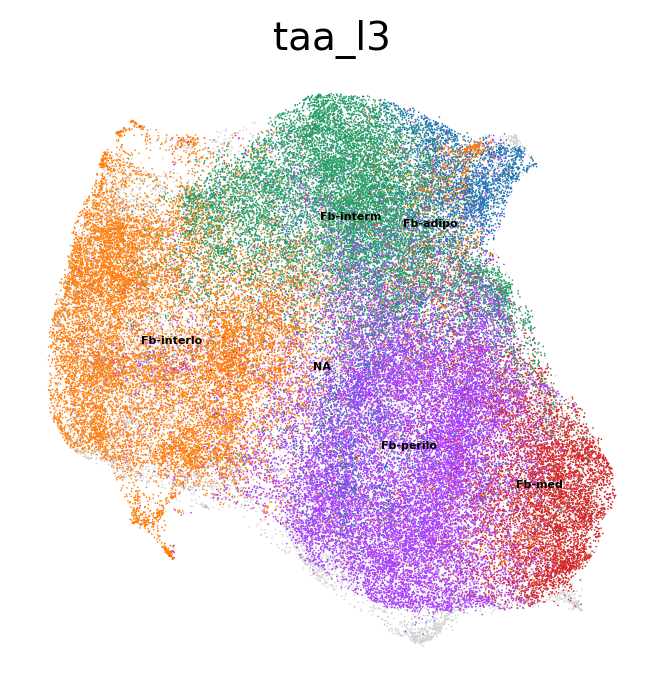

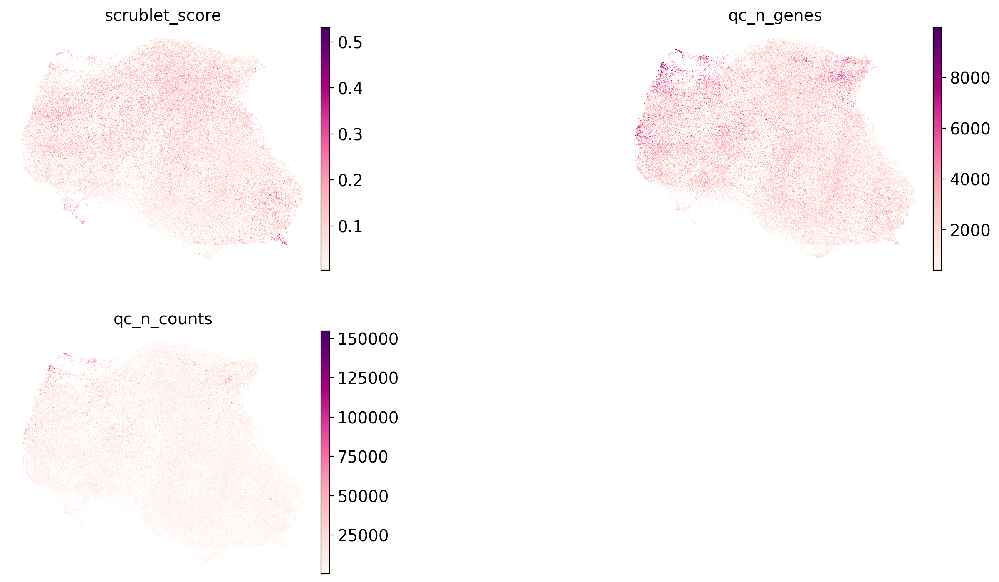

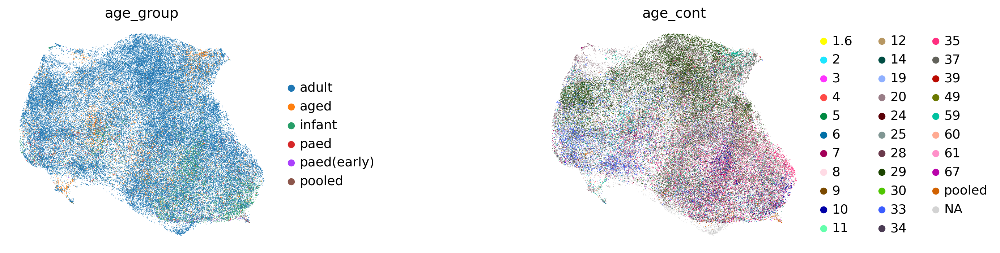

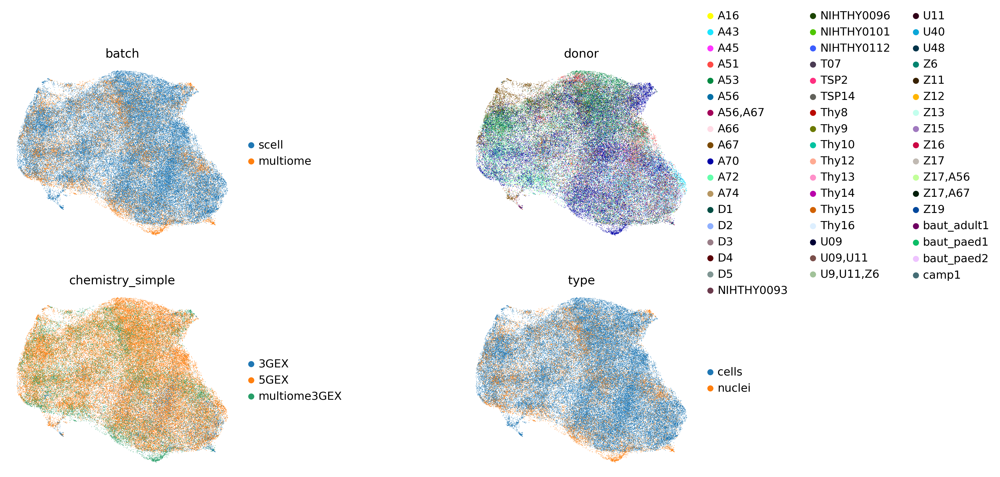

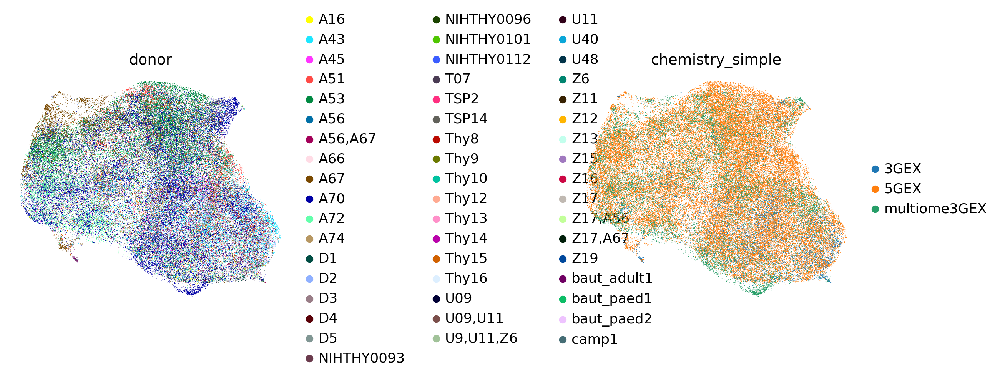

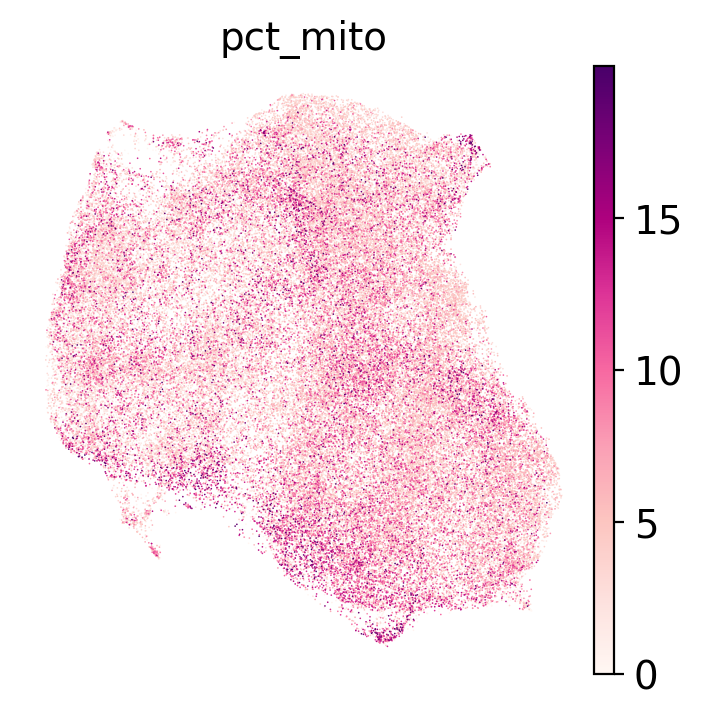

In [46]:
scvi_run = run_scvi(adata_fb_all, 
                    layer_raw = 'counts',   # X and layers['counts'] hold the same counts here
                    # Excluded genes
                    include_genes=[], exclude_cc_genes=True, exclude_mt_genes=True, 
                    exclude_vdjgenes = True, remove_cite = False,
                    # Highly variable gene selection
                    # batch_hv='type' ranks genes within cells and within nuclei and takes the
                    # median rank (seurat_v3), so the 10k HVGs are not dominated by the nuclear /
                    # intronic signal. Set back to None to reproduce the previous selection.
                    batch_hv = 'type', hvg = 10000, span = 0.5,
                    # scVI 
                    batch_scvi = BATCH_SCVI,
                    cat_cov_scvi = CAT_COVS, 
                    cont_cov_scvi = CONT_COVS,   # <-- the fix: this was silently defaulting to
                                                 # ['percent_mito'], NaN for all 15,031 nuclei
                    max_epochs=400, batch_size=2000, early_stopping = False, # early_stopping_patience = 15, early_stopping_min_delta = 10,
                    plan_kwargs = {'lr': 0.0001}, n_layers = 3, n_latent = 30, dispersion = 'gene-batch',
                                      check_val_every_n_epoch = 1,
                    # Leiden clustering
                    leiden_clustering = None, col_cell_type = 'taa_l3',
                   covs = {'doublet_metric': ['scrublet_score', 'qc_n_genes', 'qc_n_counts'],
                    'age': ['age_group', 'age_cont'],
                    'batch_mixing': ['batch', 'donor', 'chemistry_simple', 'type']})

In [47]:
# Save adata and scvi model
scvi_embed_version = 'scvi_{v1_{today}_batch{BATCH_SCVI}_3layers30lat400epochs}'
scvi_obj_version = 'Fb_scell_multiome_nuclei'

In [48]:
scvi_run['vae'].save(f'{model_path}/thyAgeing_{scvi_embed_version}_{scvi_obj_version}', save_anndata=True, overwrite=True)

In [62]:
adata_fb_integ = scvi_run['data'].copy()

In [67]:
FB_programs = {    'AR_lipogenic_axis': ["AR", "CEBPB", "ACACA"],
                   'Lipogenesis_denovo': ["FASN", "ACLY", "ACACA", "SCD", "ELOVL6"],
    'FA_uptake_transport': ["CD36", "FABP4", "FABP1", "SLC27A1", "SLC27A2", "LPL"],
    'Beta_ox_longchain': ["CPT1A", "CPT1B", "CPT2", "ACADVL", "ACADL", "ACADM", "ACADS", "ACOX1", "ABCD1", "ABCD3"],
    'Ketone_body': ["HMGCS2", "BDH1", "OXCT1"],
    'Lipolysis': ["PNPLA2", "LIPE", "MGLL"],
    'TG_synthesis': ["DGAT1", "DGAT2", "GPAM"],
    'Cholesterol_synthesis': ["HMGCR", "HMGCS1", "SQLE", "MVD", "DHCR7"],
    'Cholesterol_uptake': ["LDLR", "SCARB1"],
    'Cholesterol_efflux': ["ABCA1", "ABCG1", "APOE", "NPC1"],
    'Lipid_efflux_transport': ["ABCA1", "ABCA6", "ABCA8", "ABCA9", "ABCA10", "APOD", "APOE", "LDLR"],
    'Lipid_master_regulators': ["PPARA", "PPARG", "PPARD", "PPARGC1A", "SREBF1", "SREBF2"],
    'Lipid_droplet_storage': ["PLIN1", "PLIN2", "PLIN4", "PLIN5", "CIDEC", "CIDEA", "BSCL2", "FITM1", "FITM2", "CEBPA", "MRAP", "AQP7"],
    'Futile_cycle_uncoupling': ["UCP1", "UCP2", "UCP3"],
    'COX_PGE2_axis': ["PTGS2", "PTGES"],
    'Paracrine_adipogenic_signaling': ["BMP2", "BMP4", "WNT5A", "DKK1", "DKK3", "SFRP1", "SFRP2", "SFRP4", "PDGFC", "PDGFD"],
    'Perivascular_ECM': ["MFAP5", "CD55", "FBN1", "SEMA3C", "PI16", "PCOLCE2", "COL4A1", "COL4A2", "HIF1A", "EPAS1"],
    'Adipogenic_signal_receptors': ["PTGER1", "PTGER2", "PTGER3", "PTGER4",  "BMPR1A", "BMPR2", "LRP5", "LRP6"],
    'ECM_activated': ["COL1A1", "COL3A1", "COL5A1", "SPARC"],
    'Retinoic_acid': ["ALDH1A1", "ALDH1A2", "ALDH1A3", "CRABP2", "RARB", "CYP26B1"],
    'CR_hormone_axis': ["FGF21", "LEP", "GHRL", "GHSR", "FGFR1", "KLB"],
    'Oxidative_stress': ["HMOX1", "SOD2", "GPX3", "NQO1", "TXN", "FTL", "FTH1"],
    'FB_senescent_SASP': ["SERPINE1", "HMOX1", "LMCD1", "RASAL2", "HAS1", "THBD", "CAVIN1"],
    'Cyt': ["IL18", 'TGFB1', "IL6", "CSF1", "CCL2", "FGF18", "IGFBP5",  "IL33", "KITLG", "IL7", "CXCL12", "FLT3LG", "TSLP"],
    'Cytokine_receptive':["IL1R1", "OSMR", "LIFR", "IL6ST", "SOCS3", "NFKB1", "TNFAIP6", "TGFBR1", "TGFBR2", "TGFBR3"],
    'Stress_IEG': ["FOS", "FOSB", "JUN", "JUNB", "EGR1", "ATF3", "ZFP36",
                   "HSPA1B", "HSP90AA1", "GADD45B", "NAMPT"],
}
FB_markers2 = {
    'Oxidative_stress': ["HMOX1", "SOD2", "GPX3", "NQO1", "TXN", "FTL", "FTH1"],
    'FB_intermediate': [ "PTX3", "FOSL1", "TNFRSF12A", "IL1RL1", "HMGA1", "MT1X",
                         "CD44", "IL1R1", "OSMR", "RUNX1", "NFKB1",  "CXCL12",  "IL6", "IL18", "CSF1", "CCL2"],
   'FB_activated': [ "ACTA2", "THY1", "LMCD1","FLNA", "FLNB", "CAVIN1", "TPM4", "JARID2", "PRG4", "ALDH1A3"],
    'FB_Fibrotic': ["SNAI1", "SNAI2","TGFB1", "IL33", "COL1A1", "COL3A1", "COL5A1", "SPARC", "SP1", "JUN"],
    'Lipid_storage': ["PLIN1", "PLIN4", "FABP4", "LIPE", "CIDEC", "CIDEA", "CEBPA", "LPL", "ACACB"],
}

In [65]:
sc.pp.normalize_total(adata_fb_integ, target_sum=1e4)
sc.pp.log1p(adata_fb_integ)

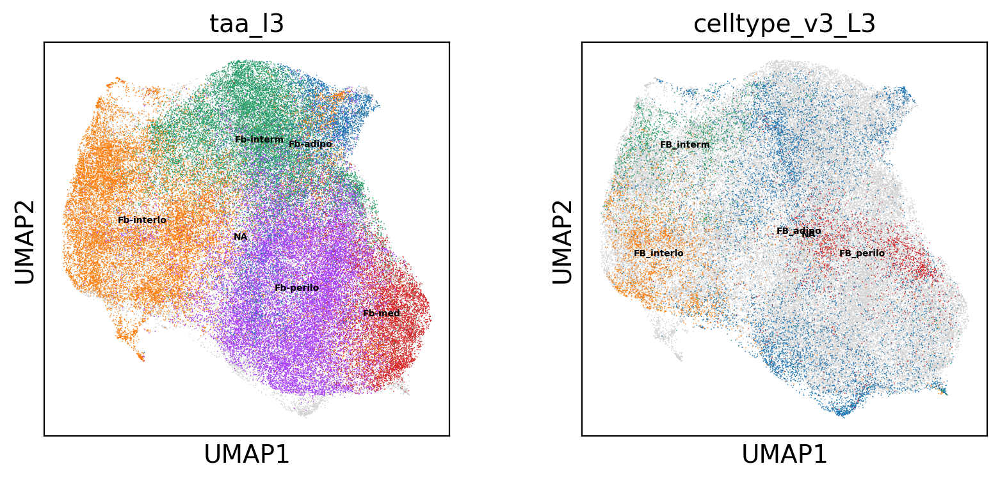

In [70]:
sc.pl.umap(adata_fb_integ, color = ['taa_l3', 'celltype_v3_L3'], legend_loc = 'on data', legend_fontsize = 5)

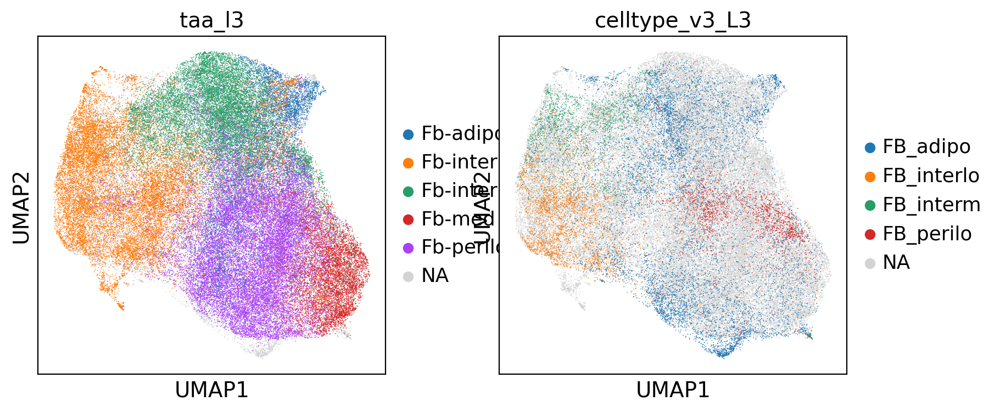

In [71]:
sc.pl.umap(adata_fb_integ, color = ['taa_l3', 'celltype_v3_L3'])

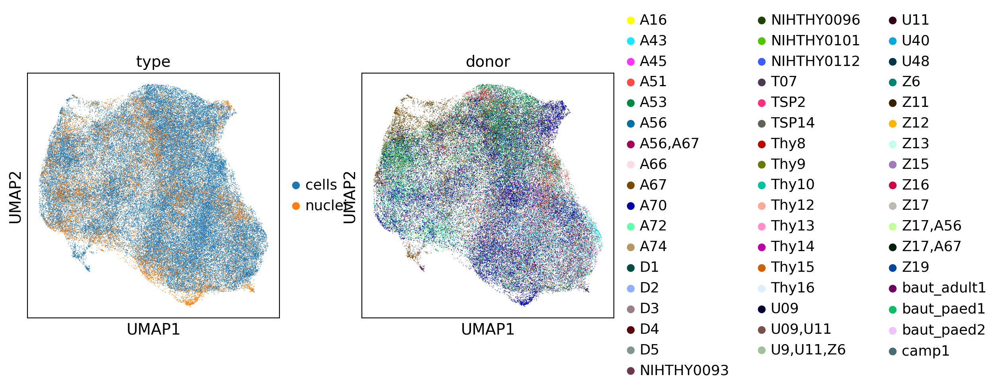

In [82]:
sc.pl.umap(adata_fb_integ, color = ['type', 'donor'])

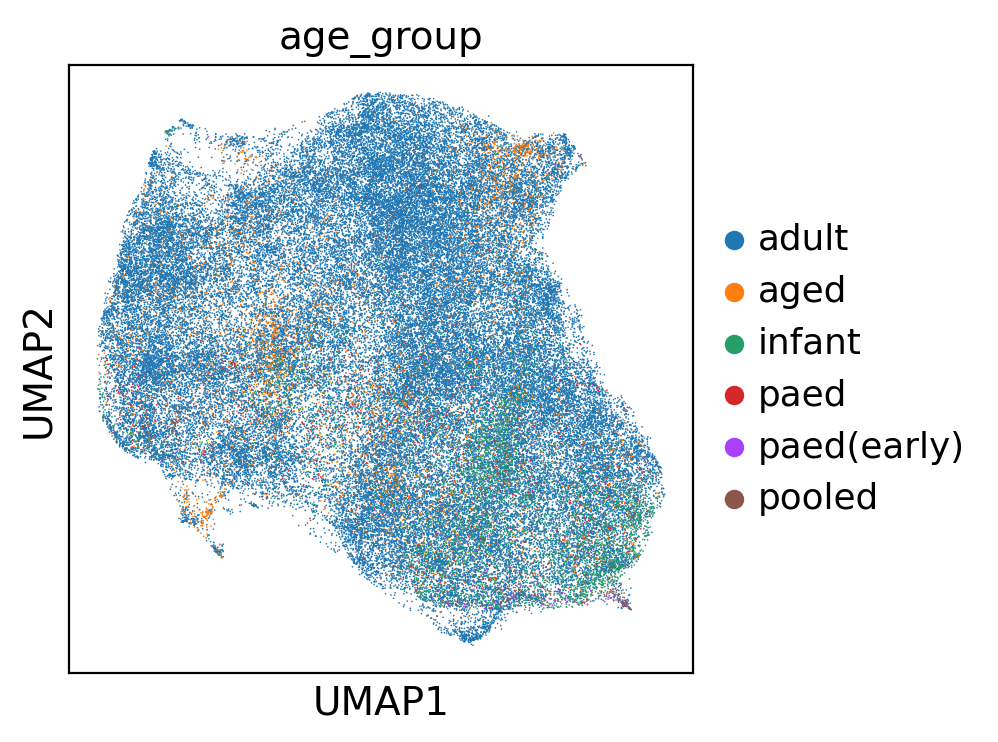

In [90]:
sc.pl.umap(adata_fb_integ, color = ['age_group'])

In [100]:
FB_programs = {    'AR_lipogenic_axis': ["AR", "CEBPB", "ACACA"],
                   'Lipogenesis_denovo': ["FASN", "ACLY", "ACACA", "SCD", "ELOVL6"],
    'FA_uptake_transport': ["CD36", "FABP4", "FABP1", "SLC27A1", "SLC27A2", "LPL"],
    'Beta_ox_longchain': ["CPT1A", "CPT1B", "CPT2", "ACADVL", "ACADL", "ACADM", "ACADS", "ACOX1", "ABCD1", "ABCD3"],
    'Ketone_body': ["HMGCS2", "BDH1", "OXCT1"],
    'Lipolysis': ["PNPLA2", "LIPE", "MGLL"],
    'TG_synthesis': ["DGAT1", "DGAT2", "GPAM"],
    'Cholesterol_synthesis': ["HMGCR", "HMGCS1", "SQLE", "MVD", "DHCR7"],
    'Cholesterol_uptake': ["LDLR", "SCARB1"],
    'Cholesterol_efflux': ["ABCA1", "ABCG1", "APOE", "NPC1"],
    'Lipid_efflux_transport': ["ABCA1", "ABCA6", "ABCA8", "ABCA9", "ABCA10", "APOD", "APOE", "LDLR"],
    'Lipid_master_regulators': ["PPARA", "PPARG", "PPARD", "PPARGC1A", "SREBF1", "SREBF2"],
    'Lipid_droplet_storage': ["PLIN1", "PLIN2", "PLIN4", "PLIN5", "CIDEC", "CIDEA", "BSCL2", "FITM1", "FITM2", "CEBPA", "MRAP", "AQP7"],
    'Futile_cycle_uncoupling': ["UCP1", "UCP2", "UCP3"],
    'COX_PGE2_axis': ["PTGS2", "PTGES"],
    'Paracrine_adipogenic_signaling': ["BMP2", "BMP4", "WNT5A", "DKK1", "DKK3", "SFRP1", "SFRP2", "SFRP4", "PDGFC", "PDGFD"],
    'Perivascular_ECM': ["MFAP5", "CD55", "FBN1", "SEMA3C", "PI16", "PCOLCE2", "COL4A1", "COL4A2", "HIF1A", "EPAS1"],
    'Adipogenic_signal_receptors': ["PTGER1", "PTGER2", "PTGER3", "PTGER4",  "BMPR1A", "BMPR2", "LRP5", "LRP6"],
    'ECM_activated': ["COL1A1", "COL3A1", "COL5A1", "SPARC"],
    'Retinoic_acid': ["ALDH1A1", "ALDH1A2", "ALDH1A3", "CRABP2", "RARB", "CYP26B1"],
    'CR_hormone_axis': ["FGF21", "LEP", "GHRL", "GHSR", "FGFR1", "KLB"],
    'Oxidative_stress': ["HMOX1", "SOD2", "GPX3", "NQO1", "TXN", "FTL", "FTH1"],
    'FB_senescent_SASP': ["SERPINE1", "HMOX1", "LMCD1", "RASAL2", "HAS1", "THBD", "CAVIN1"],
    'Cyt': ["IL18", 'TGFB1', "IL6", "CSF1", "CCL2", "FGF18", "IGFBP5",  "IL33", "KITLG", "IL7", "CXCL12", "FLT3LG", "TSLP"],
    'Cytokine_receptive':["IL1R1", "OSMR", "LIFR", "IL6ST", "SOCS3", "NFKB1", "TNFAIP6", "TGFBR1", "TGFBR2", "TGFBR3"],
    'Stress_IEG': ["FOS", "FOSB", "JUN", "JUNB", "EGR1", "ATF3", "ZFP36",
                   "HSPA1B", "HSP90AA1", "GADD45B", "NAMPT"],
}
FB_markers2 = {
    'Oxidative_stress': ["HMOX1", "SOD2", "GPX3", "NQO1", "TXN", "FTL", "FTH1"],
    'FB_intermediate': [ "PTX3", "FOSL1", "TNFRSF12A", "IL1RL1", "HMGA1", "MT1X",
                         "CD44", "IL1R1", "OSMR", "RUNX1", "NFKB1",  "CXCL12",  "IL6", "IL18", "CSF1", "CCL2"],
   'FB_activated': [ "ACTA2", "THY1", "LMCD1","FLNA", "FLNB", "CAVIN1", "TPM4", "JARID2", "PRG4", "ALDH1A3"],
    'FB_Fibrotic': ["SNAI1", "SNAI2","TGFB1", "IL33", "COL1A1", "COL3A1", "COL5A1", "SPARC", "SP1", "JUN"],
    'Lipid_storage': ["PLIN1", "PLIN4", "FABP4", "LIPE", "CIDEC", "CIDEA", "CEBPA", "LPL", "ACACB"],
}

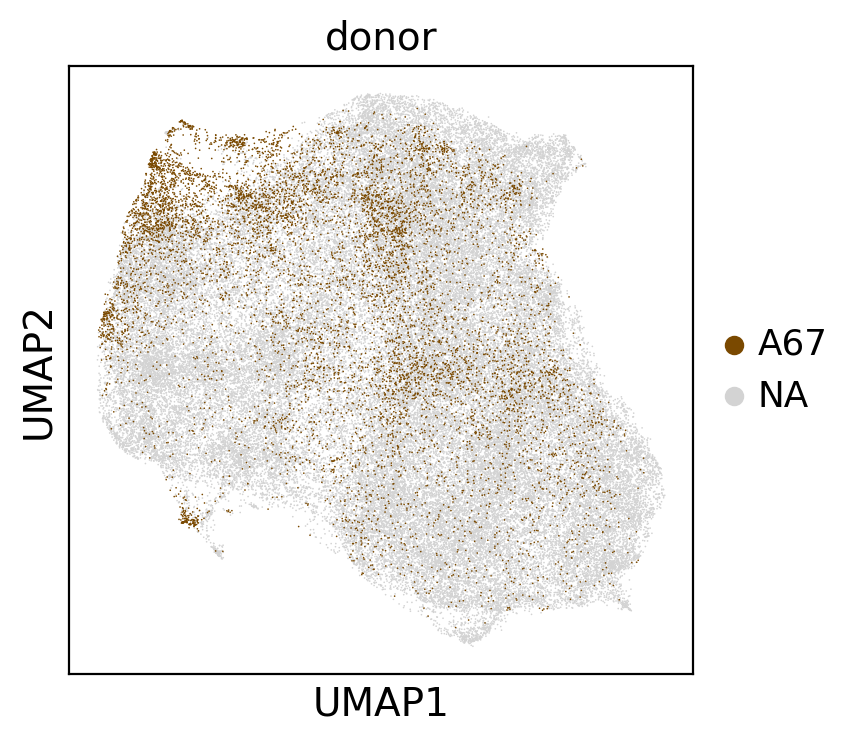

In [83]:
sc.pl.umap(adata_fb_integ, color = ['donor'], groups = ['A67'])

In [72]:
fbs_mrkrs_full = {'General': ['PDGFRA', 'VIM', 'DCN', 'PDPN', 'THY1'],
             'Interlobular (PI16 progenitor)': ['MFAP5', 'CD55', 'FBN1','SEMA3C', 'PI16','PCOLCE2'],
             'Intermediate': ['PTX3', 'FOSL1', 'TNFRSF12A', 'HMOX1', 'IL1RL1', 'HMGA1','MT1X'],
             'Parenchymal': ['C7', 'APOD', 'FBLN5', 'MFAP4', 'LUM', 'FMO2'],
             'Perilobular (progenitor)': ['COL15A1', 'COLEC11', 'ALDH1A2', 'PTN', 'HAND2', 'LAMC3'],
             'Medullary (antigen-presenting)': ['HLA-DRA',  'CD74', 'FRZB', 'CCL19', 'CCL21', 'IL33'],
             'FDC':['CXCL13', 'FDCSP'],
             'Adipose': ['CXCL12','PPARG', 'APOE', 'PPP1R1A', 'PLIN1', 'LIPE','CIDEA', 'MRAP', 'AQP7']
             }
fbs_mrkrs_full_lst=[]
[fbs_mrkrs_full_lst.extend(fbs_mrkrs_full[key]) for key in fbs_mrkrs_full.keys()]

[None, None, None, None, None, None, None, None]

In [ ]:
sc.pl.umap(adata_fb_integ, color = [gene for gene in fbs_mrkrs_full_lst if gene in adata_fb_integ.var_names])

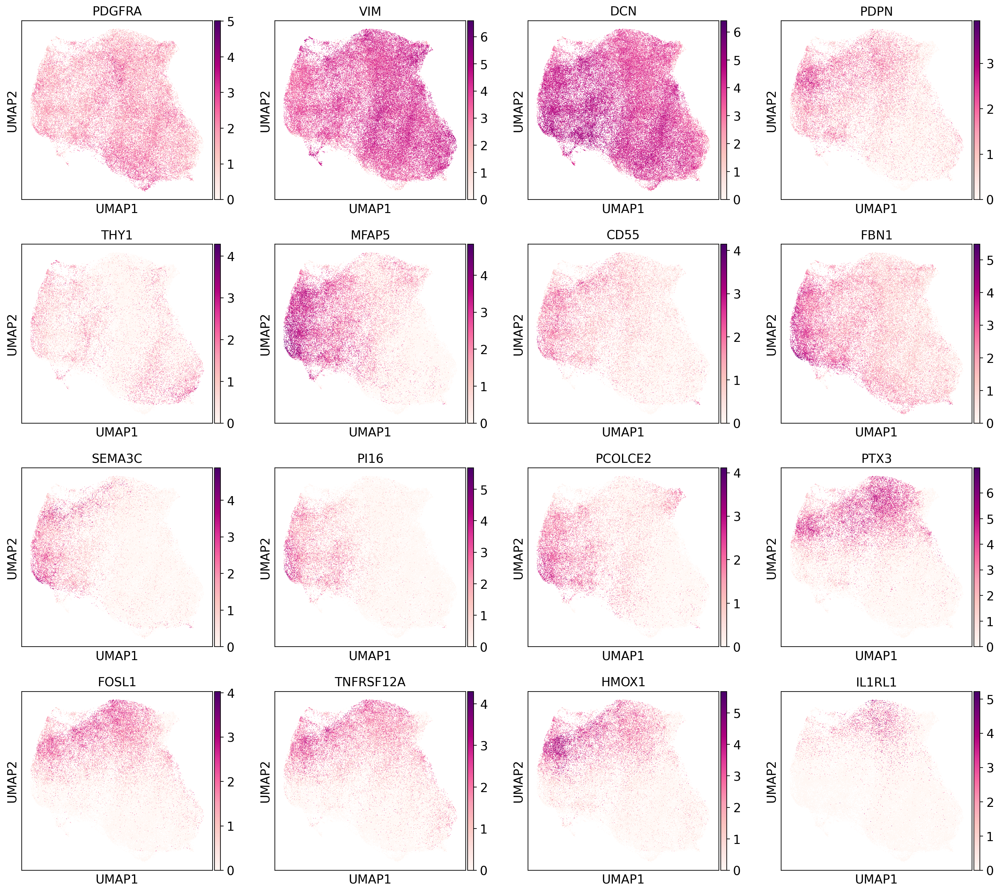

In [80]:
sc.pl.umap(adata_fb_integ, color = ['PDGFRA',
 'VIM',
 'DCN',
 'PDPN',
 'THY1',
 'MFAP5',
 'CD55',
 'FBN1',
 'SEMA3C',
 'PI16',
 'PCOLCE2',
 'PTX3',
 'FOSL1',
 'TNFRSF12A',
 'HMOX1',
 'IL1RL1'])

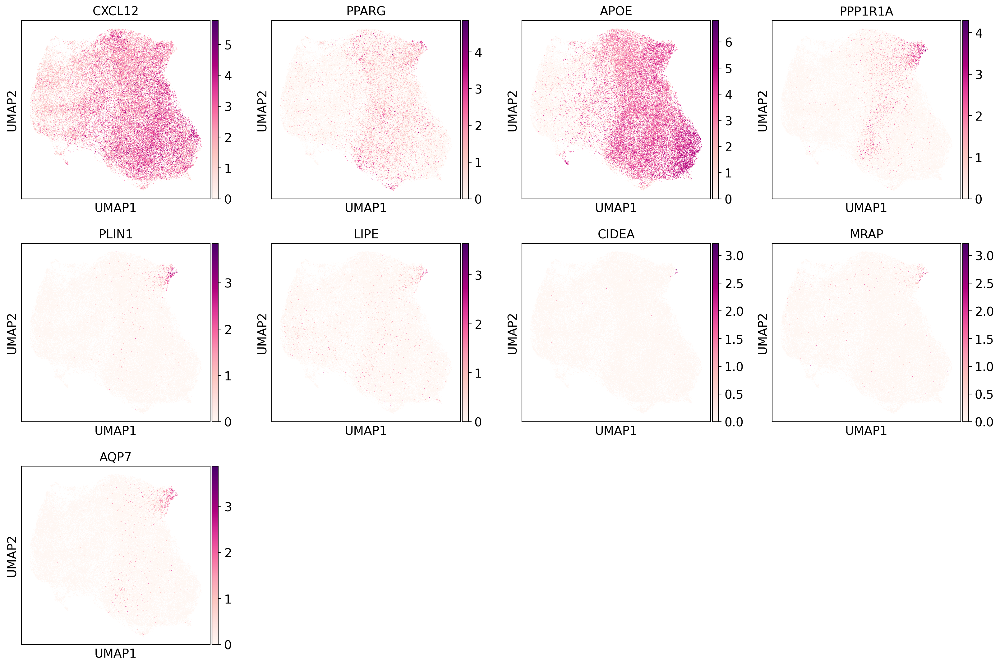

In [87]:
sc.pl.umap(adata_fb_integ, color = ['CXCL12','PPARG', 'APOE', 'PPP1R1A', 'PLIN1', 'LIPE','CIDEA', 'MRAP', 'AQP7'])

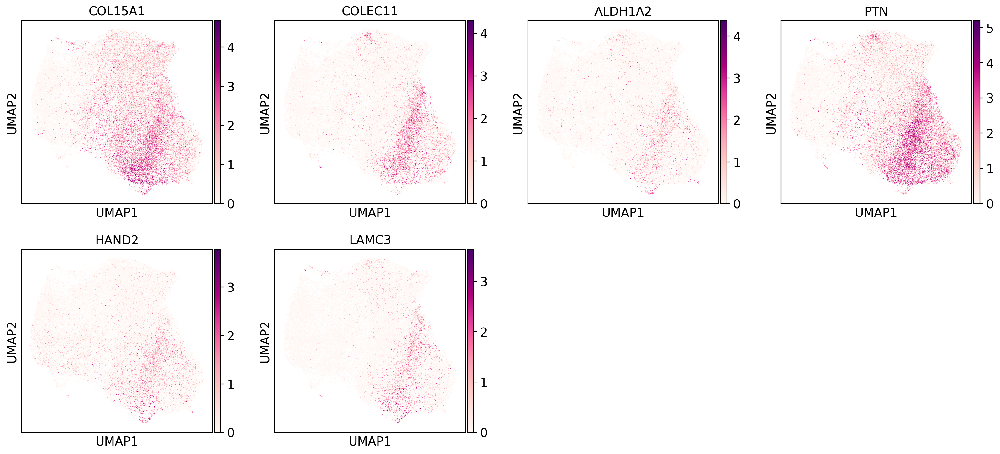

In [92]:
sc.pl.umap(adata_fb_integ, color = ['COL15A1', 'COLEC11', 'ALDH1A2', 'PTN', 'HAND2', 'LAMC3'])

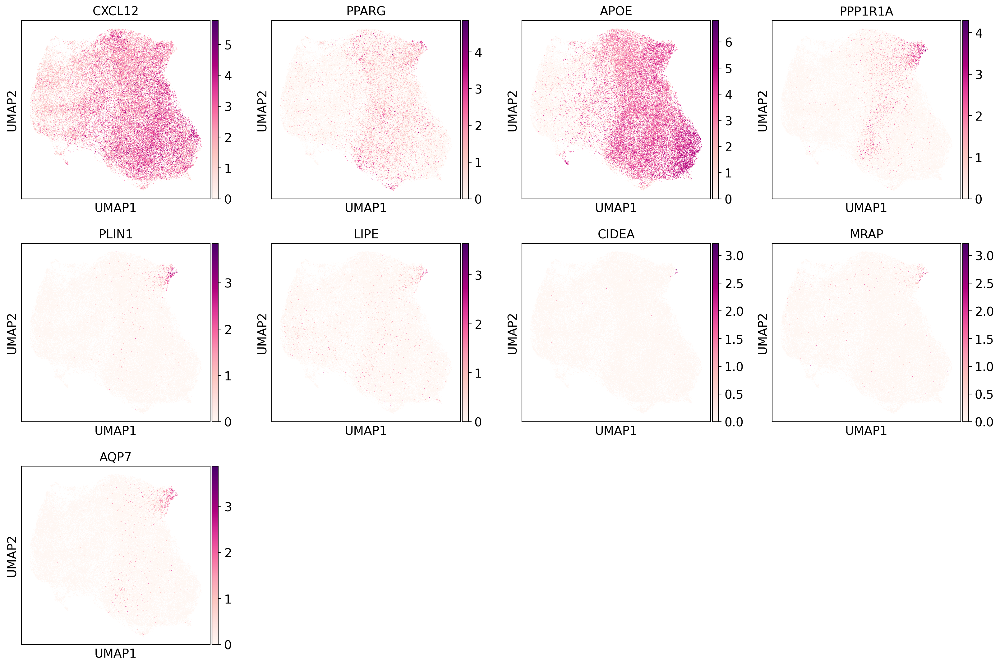

In [91]:
sc.pl.umap(adata_fb_integ, color = ['CXCL12','PPARG', 'APOE', 'PPP1R1A', 'PLIN1', 'LIPE','CIDEA', 'MRAP', 'AQP7'])

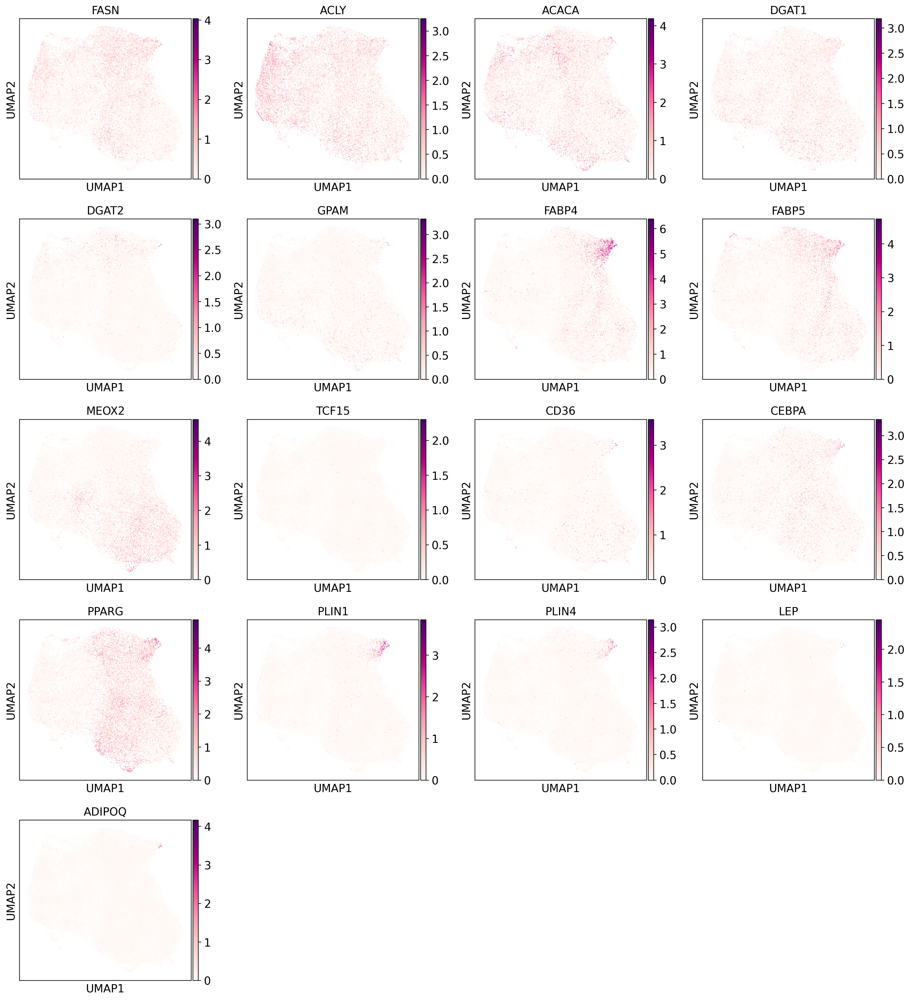

In [89]:
sc.pl.umap(adata_fb_integ, color = ['FASN', 'ACLY', 'ACACA', 'DGAT1', 'DGAT2', 'GPAM', 
                                    'FABP4', 'FABP5', 'MEOX2', 'TCF15', 'CD36', 
                                    'CEBPA', 'PPARG', 'PLIN1', 'PLIN4', 'LEP', 'ADIPOQ'])

In [103]:
fb_signature = ['FAP', 'FGF14', 'FLNB', 'ITGBL1', 'LOXL1', 'MOXD1', "NEK6", "SAMD11", 'SLC39A10', 'SMOC2']

In [107]:
thymus_fibrosis = ["TGFB1", "SNAI1", "SNAI2", "ACTA2", "COL1A1", "COL1A2", "COL3A1", "COL5A1","LOXL1", "SPARC"]

In [108]:
sc.tl.score_genes(adata_fb_integ, gene_list = thymus_fibrosis, score_name='Fb_fibrotic')

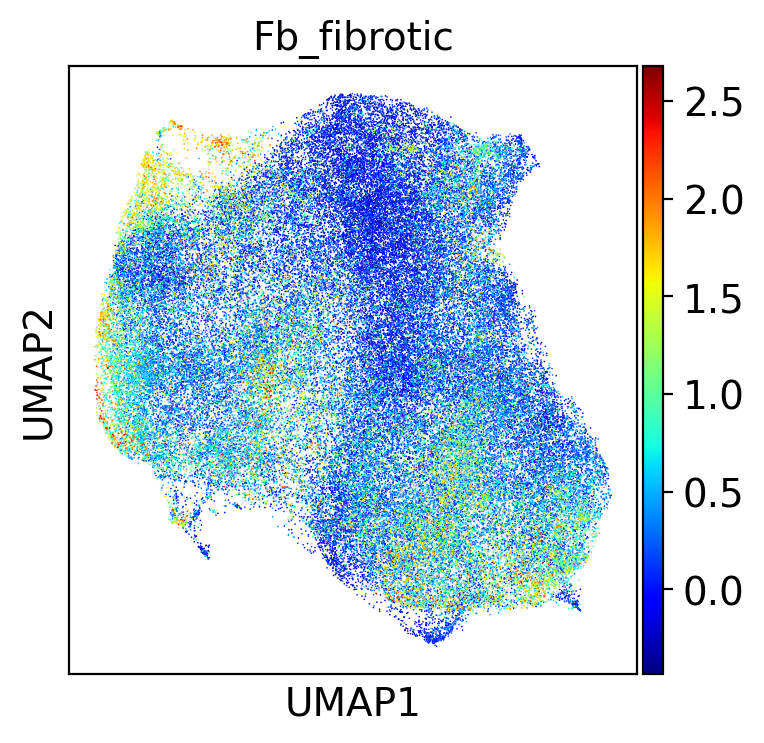

In [109]:
sc.pl.umap(adata_fb_integ, color = 'Fb_fibrotic', cmap = 'jet')

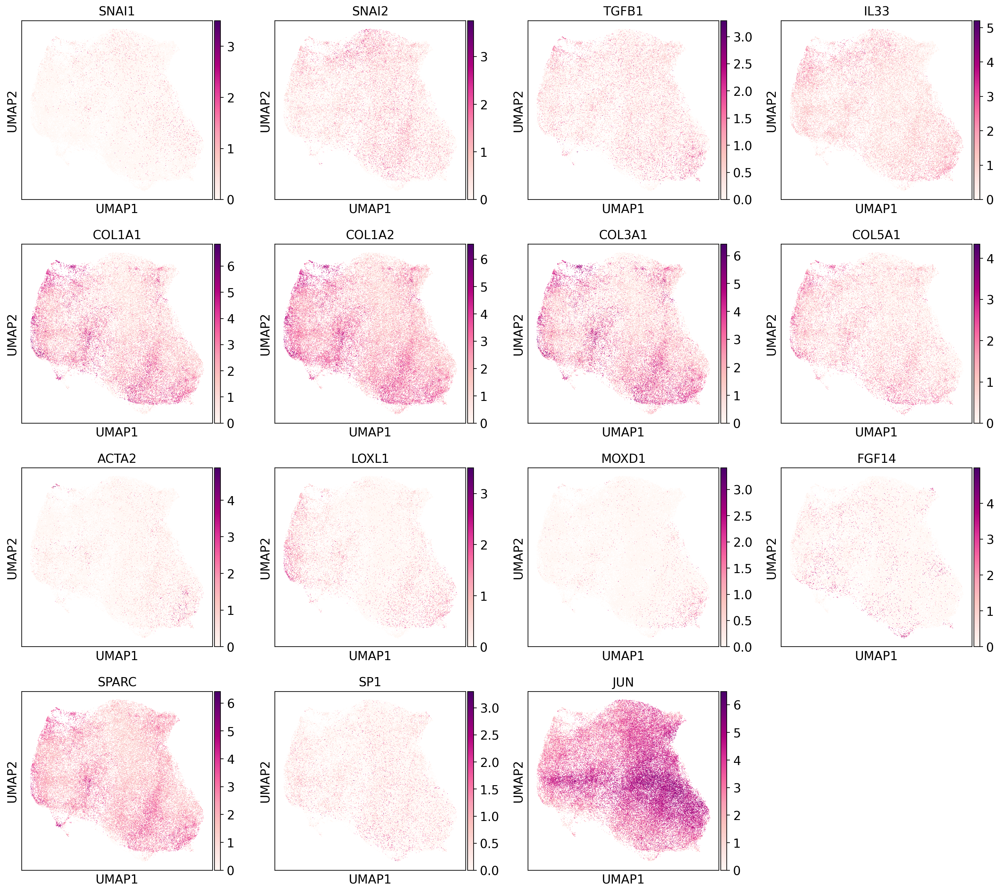

In [106]:
sc.pl.umap(adata_fb_integ, color = ["SNAI1", "SNAI2","TGFB1", "IL33", "COL1A1", "COL1A2", "COL3A1", "COL5A1", 
"ACTA2", "LOXL1", "MOXD1", "FGF14", "SPARC", "SP1", "JUN"])

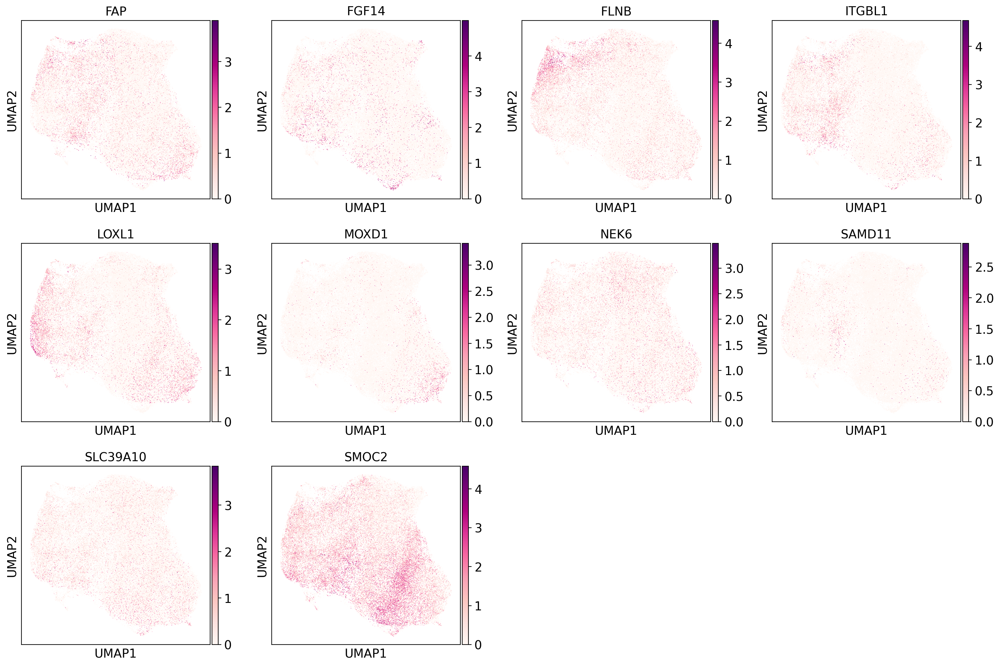

In [104]:
sc.pl.umap(adata_fb_integ, color = fb_signature)

In [93]:
from utils_vk8 import run_leiden

In [94]:
run_leiden

<function utils_vk8.run_leiden(adata, resolutions, key_name, restrict_to=None, legend_loc='on data', legend_fontsize=4)>

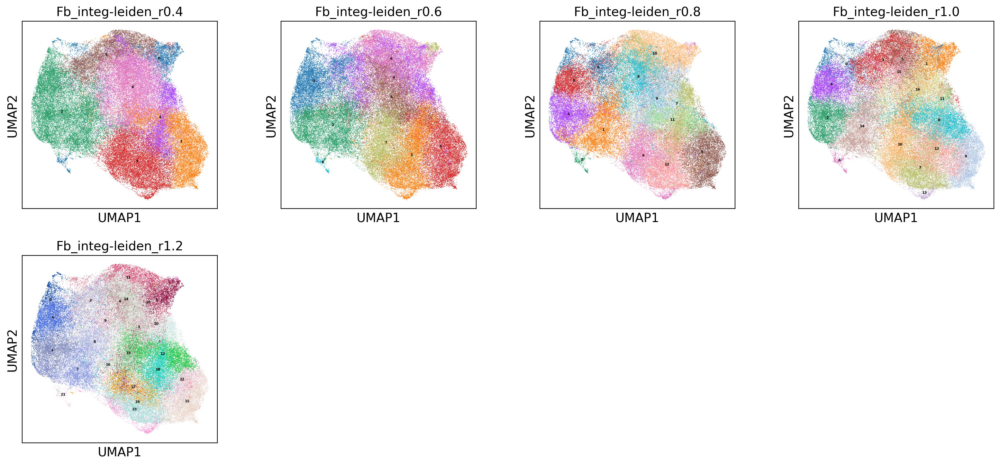

In [ ]:
run_leiden(adata_fb_integ, resolutions = [0.4, 0.6, 0.8, 1.0, 1.2], key_name = 'Fb_integ')

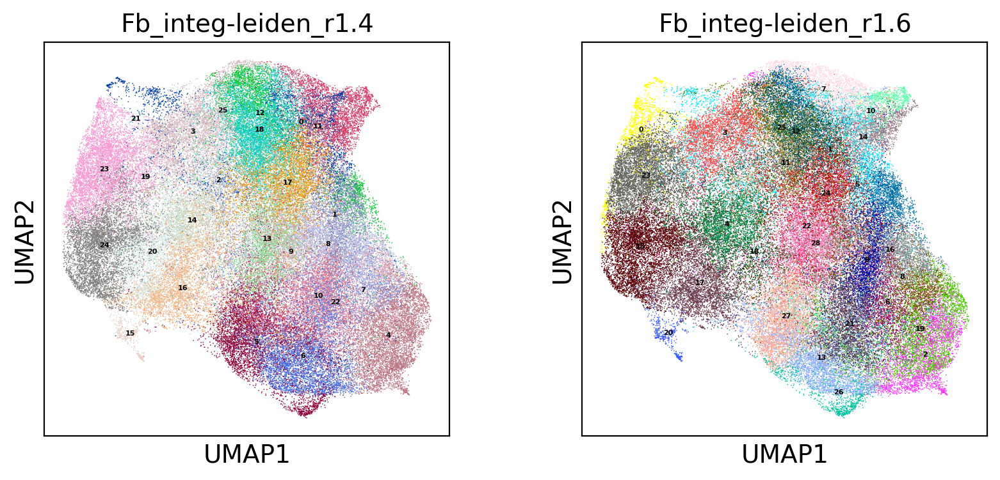

In [98]:
run_leiden(adata_fb_integ, resolutions = [1.4, 1.6], key_name = 'Fb_integ')

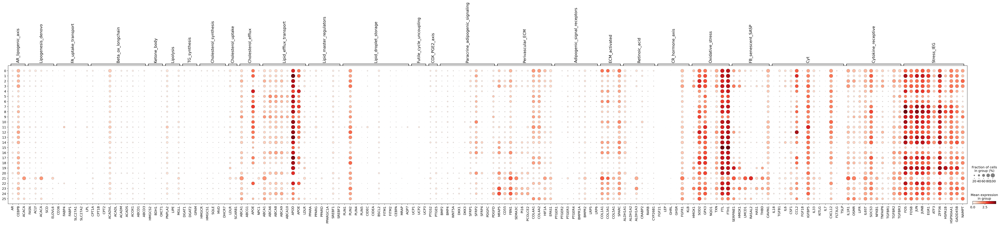

In [102]:
sc.pl.dotplot(adata_fb_integ, var_names = FB_programs, groupby = 'Fb_integ-leiden_r1.4')

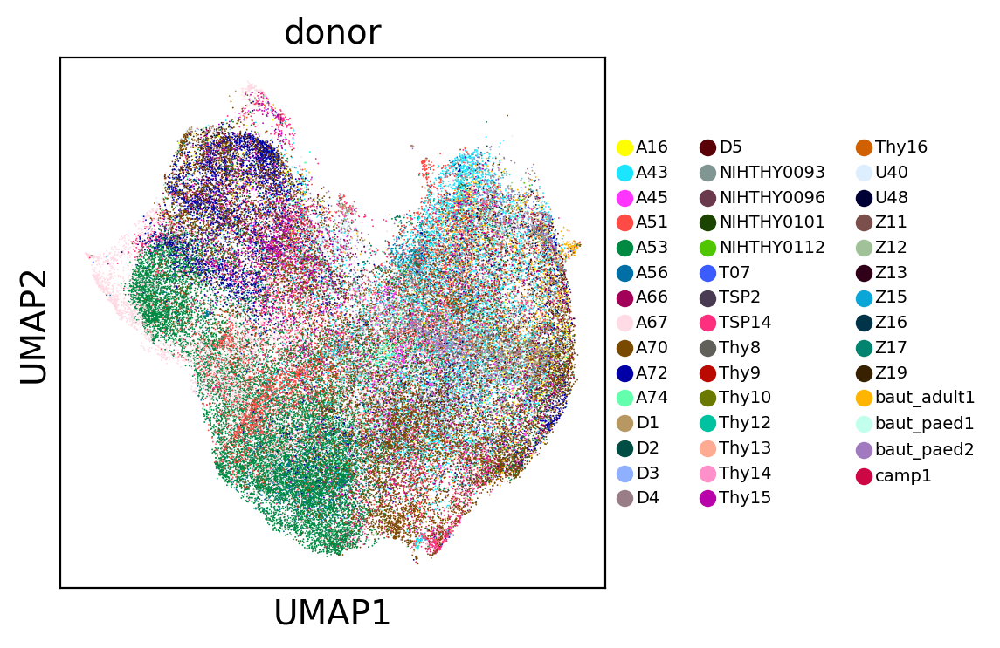

In [14]:
sc.pl.umap(adata_fbs_scell, color = ['donor'], legend_fontsize = 7)

In [15]:
adata_fbs_scell

AnnData object with n_obs × n_vars = 70258 × 26105
    obs: 'sample', 'donor', 'library', 'chemistry_simple', 'chemistry_detail', 'origin_institute', 'study', 'public_data', 'sort', 'sort_type', 'age_group', 'age', 'age_months', 'sex', 'anno_status', 'qc_status', 'taa_l5', 'taa_l4', 'taa_l3', 'taa_l2', 'taa_l1', 'taa_l0', 'n_counts', 'n_genes', 'percent_mito', 'percent_ribo', 'percent_hb', 'scrublet_score'
    var: 'gene_ids', 'gene_name', 'n_cells'
    uns: 'taa_l3_colors', 'donor_colors'
    obsm: 'X_scVI', 'X_umap'

In [16]:
from utils_vk8 import regen_embed, run_leiden

In [21]:
sc.pp.neighbors(adata_fbs_scell, use_rep = 'X_scVI')

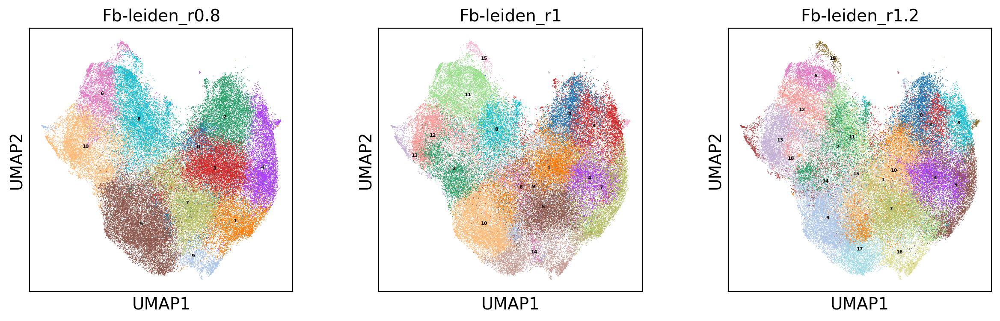

In [22]:
run_leiden(adata_fbs_scell, resolutions = [0.8, 1, 1.2], key_name = 'Fb')

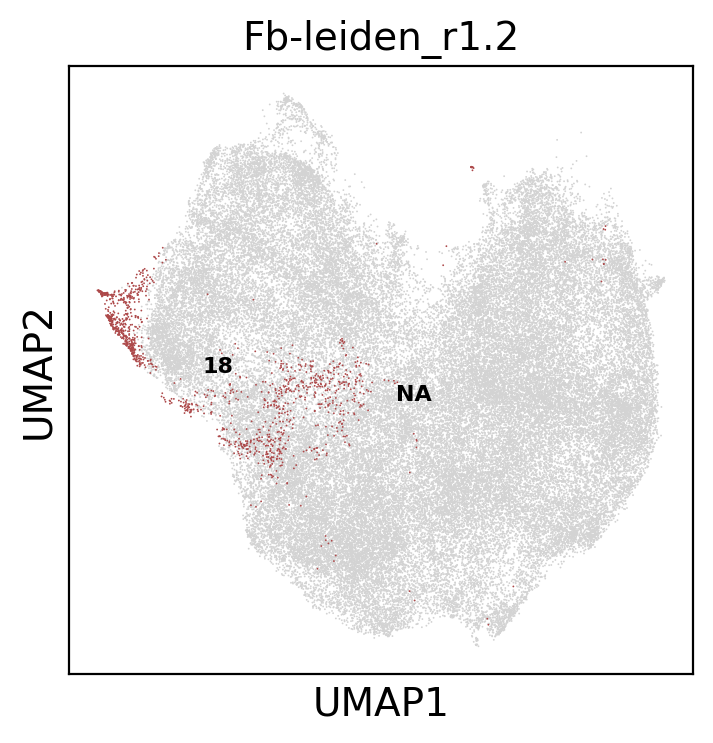

In [29]:
sc.pl.umap(adata_fbs_scell, color = ['Fb-leiden_r1.2'], groups = '18', legend_loc = 'on data', legend_fontsize = 8)

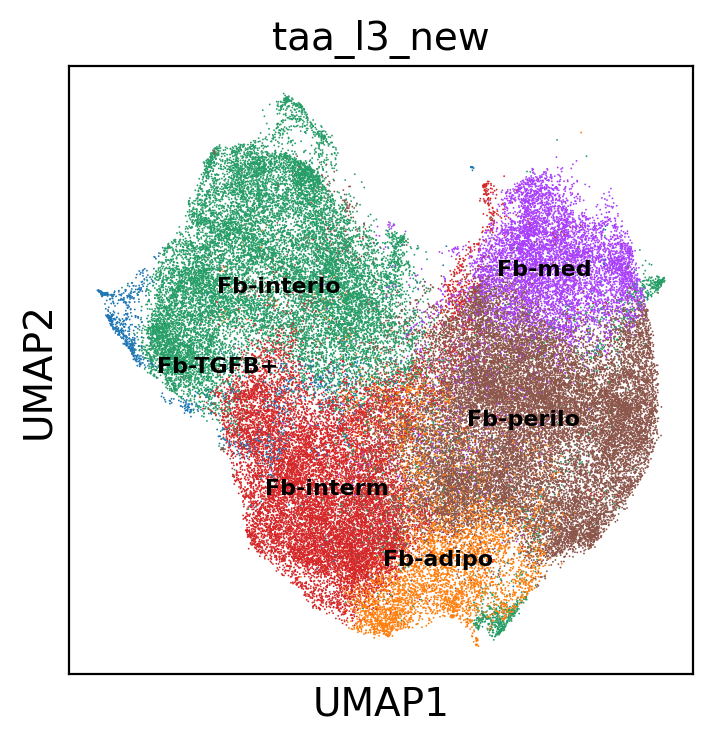

In [34]:
sc.pl.umap(adata_fbs_scell, color = ['taa_l3_new'], legend_loc = 'on data', legend_fontsize = 8)

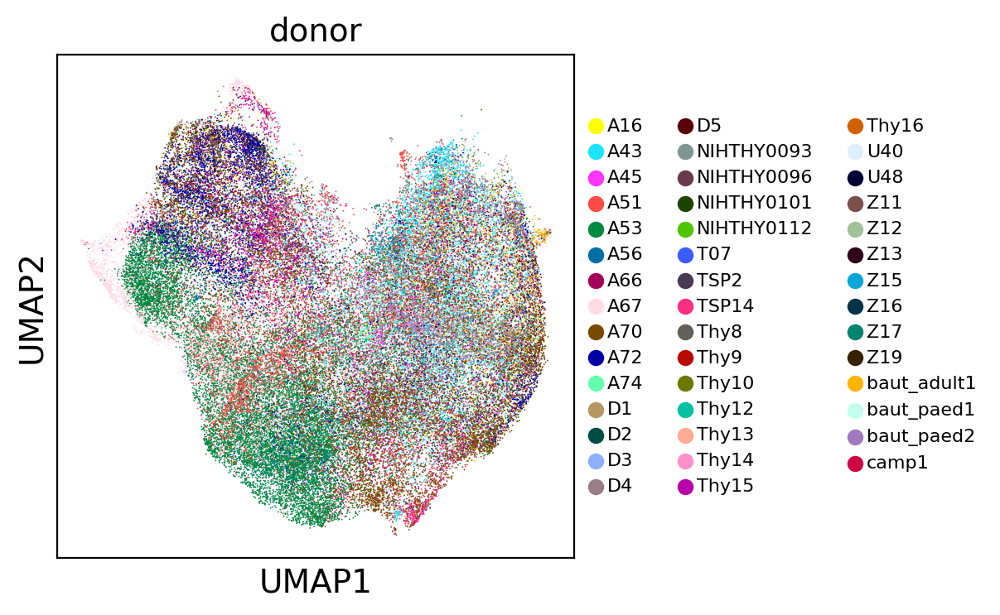

In [35]:
sc.pl.umap(adata_fbs_scell, color = ['donor'], legend_fontsize = 8)

In [31]:
adata_fbs_scell.obs['taa_l3_new'] = adata_fbs_scell.obs['taa_l3'].copy()
adata_fbs_scell.obs['taa_l3_new'] = adata_fbs_scell.obs['taa_l3_new'].astype(str)

In [32]:
adata_fbs_scell.obs.loc[adata_fbs_scell.obs['Fb-leiden_r1.2'] == '18', 'taa_l3_new'] = 'Fb-TGFB+'

In [33]:
pd.crosstab(adata_fbs_scell.obs['taa_l3_new'], adata_fbs_scell.obs['donor'])

donor,A16,A43,A45,A51,A53,A56,A66,A67,A70,A72,A74,D1,D2,D3,D4,D5,NIHTHY0093,NIHTHY0096,NIHTHY0101,NIHTHY0112,T07,TSP2,TSP14,Thy8,Thy9,Thy10,Thy12,Thy13,Thy14,Thy15,Thy16,U40,U48,Z11,Z12,Z13,Z15,Z16,Z17,Z19,baut_adult1,baut_paed1,baut_paed2,camp1
taa_l3_new,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Fb-TGFB+,0,5,0,3,52,6,0,1079,17,5,0,9,1,0,1,1,0,0,0,0,1,1,70,1,0,0,0,0,0,17,3,5,0,0,0,0,0,0,0,0,1,2,4,0
Fb-adipo,17,484,61,255,1387,153,21,116,1572,43,72,16,1,2,2,0,34,0,0,0,0,87,610,0,0,0,0,0,2,155,4,45,0,0,23,4,0,0,10,0,24,2,14,0
Fb-interlo,167,865,278,548,3826,143,381,1683,2807,3050,144,125,24,10,23,76,41,0,8,3,0,64,2000,1,2,1,2,1,3,737,68,410,1,1,85,206,0,1,78,14,244,40,202,0
Fb-interm,1,356,25,2047,8284,1259,6,1482,665,176,142,2,1,0,5,3,46,0,0,0,0,7,136,0,0,0,0,0,0,39,6,8,0,0,14,6,0,0,5,0,73,0,21,0
Fb-med,38,1953,15,697,214,247,181,187,396,105,49,162,58,86,109,393,162,0,7,10,44,1,86,6,0,1,1,0,0,216,0,295,10,4,103,21,7,6,98,0,1094,10,429,16
Fb-perilo,304,3245,453,1344,1822,993,795,1752,3836,556,752,685,98,41,128,392,367,4,20,18,19,356,445,10,2,5,1,3,20,256,9,865,12,10,361,177,8,5,252,9,1210,228,1190,5


In [30]:
pd.crosstab(adata_fbs_scell.obs['Fb-leiden_r1.2'], adata_fbs_scell.obs['donor'])

donor,A16,A43,A45,A51,A53,A56,A66,A67,A70,A72,A74,D1,D2,D3,D4,D5,NIHTHY0093,NIHTHY0096,NIHTHY0101,NIHTHY0112,T07,TSP2,TSP14,Thy8,Thy9,Thy10,Thy12,Thy13,Thy14,Thy15,Thy16,U40,U48,Z11,Z12,Z13,Z15,Z16,Z17,Z19,baut_adult1,baut_paed1,baut_paed2,camp1
Fb-leiden_r1.2,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,11,1630,15,494,114,220,52,76,295,43,20,15,6,10,13,63,84,0,3,4,12,1,5,0,0,0,0,0,1,187,0,80,1,2,45,9,6,4,59,0,757,1,115,1
1,6,292,128,125,729,560,18,119,501,74,73,18,12,3,5,15,35,0,1,1,1,18,34,0,0,0,0,0,2,13,4,95,1,0,59,3,3,0,56,0,41,0,42,1
2,2,171,9,467,692,48,10,457,487,133,41,34,4,2,10,3,24,0,0,0,0,3,733,0,0,0,0,0,0,253,6,166,0,0,9,3,0,0,31,0,11,2,34,1
3,8,211,2,305,91,73,85,122,93,37,40,43,12,18,38,153,25,0,0,2,4,0,78,0,0,0,0,0,0,31,0,236,7,0,50,9,1,1,60,0,178,4,207,1
4,86,1037,70,327,188,43,134,102,437,16,78,339,51,13,53,88,92,1,4,3,8,57,13,4,1,3,0,1,6,77,0,403,3,3,86,44,0,4,43,5,247,142,629,2
5,159,464,51,69,380,121,375,239,1092,278,78,246,22,15,37,190,102,3,15,11,3,178,97,4,1,2,1,1,7,18,0,94,1,6,78,32,2,0,43,4,429,60,148,1
6,91,68,39,14,82,4,111,47,562,1021,5,42,11,5,8,58,5,0,6,3,0,16,85,1,2,1,2,1,3,59,5,75,1,0,21,77,0,1,11,10,8,34,34,0
7,11,809,119,268,692,271,125,860,1725,121,262,1,0,0,0,28,60,0,0,0,0,56,287,0,0,0,0,0,2,109,0,152,1,0,106,77,0,0,23,0,213,2,200,0
8,38,395,1,63,37,11,101,45,139,64,2,166,52,68,79,226,67,0,4,6,33,1,61,8,0,1,1,0,0,24,0,84,3,0,31,10,1,0,9,0,399,12,178,12


In [26]:
FB_programs = {    'AR_lipogenic_axis': ["AR", "CEBPB", "ACACA"],
                   'Lipogenesis_denovo': ["FASN", "ACLY", "ACACA", "SCD", "ELOVL6"],
    'FA_uptake_transport': ["CD36", "FABP4", "FABP1", "SLC27A1", "SLC27A2", "LPL"],
    'Beta_ox_longchain': ["CPT1A", "CPT1B", "CPT2", "ACADVL", "ACADL", "ACADM", "ACADS", "ACOX1", "ABCD1", "ABCD3"],
    'Ketone_body': ["HMGCS2", "BDH1", "OXCT1"],
    'Lipolysis': ["PNPLA2", "LIPE", "MGLL"],
    'TG_synthesis': ["DGAT1", "DGAT2", "GPAM"],
    'Cholesterol_synthesis': ["HMGCR", "HMGCS1", "SQLE", "MVD", "DHCR7"],
    'Cholesterol_uptake': ["LDLR", "SCARB1"],
    'Cholesterol_efflux': ["ABCA1", "ABCG1", "APOE", "NPC1"],
    'Lipid_efflux_transport': ["ABCA1", "ABCA6", "ABCA8", "ABCA9", "ABCA10", "APOD", "APOE", "LDLR"],
    'Lipid_master_regulators': ["PPARA", "PPARG", "PPARD", "PPARGC1A", "SREBF1", "SREBF2"],
    'Lipid_droplet_storage': ["PLIN1", "PLIN2", "PLIN4", "PLIN5", "CIDEC", "CIDEA", "BSCL2", "FITM1", "FITM2", "CEBPA", "MRAP", "AQP7"],
    'Futile_cycle_uncoupling': ["UCP1", "UCP2", "UCP3"],
    'COX_PGE2_axis': ["PTGS2", "PTGES"],
    'Paracrine_adipogenic_signaling': ["BMP2", "BMP4", "WNT5A", "DKK1", "DKK3", "SFRP1", "SFRP2", "SFRP4", "PDGFC", "PDGFD"],
    'Perivascular_ECM': ["MFAP5", "CD55", "FBN1", "SEMA3C", "PI16", "PCOLCE2", "COL4A1", "COL4A2", "HIF1A", "EPAS1"],
    'Adipogenic_signal_receptors': ["PTGER1", "PTGER2", "PTGER3", "PTGER4",  "BMPR1A", "BMPR2", "LRP5", "LRP6"],
    'ECM_activated': ["COL1A1", "COL3A1", "COL5A1", "SPARC"],
    'Retinoic_acid': ["ALDH1A1", "ALDH1A2", "ALDH1A3", "CRABP2", "RARB", "CYP26B1"],
    'CR_hormone_axis': ["FGF21", "LEP", "GHRL", "GHSR", "FGFR1", "KLB"],
    'Oxidative_stress': ["HMOX1", "SOD2", "GPX3", "NQO1", "TXN", "FTL", "FTH1"],
    'FB_senescent_SASP': ["SERPINE1", "HMOX1", "LMCD1", "RASAL2", "HAS1", "THBD", "CAVIN1"],
    'Cyt': ["IL18", 'TGFB1', "IL6", "CSF1", "CCL2", "FGF18", "IGFBP5",  "IL33", "KITLG", "IL7", "CXCL12", "FLT3LG", "TSLP"],
    'Cytokine_receptive':["IL1R1", "OSMR", "LIFR", "IL6ST", "SOCS3", "NFKB1", "TNFAIP6", "TGFBR1", "TGFBR2", "TGFBR3"],
    'Stress_IEG': ["FOS", "FOSB", "JUN", "JUNB", "EGR1", "ATF3", "ZFP36",
                   "HSPA1B", "HSP90AA1", "GADD45B", "NAMPT"],
}
FB_markers2 = {
    'Oxidative_stress': ["HMOX1", "SOD2", "GPX3", "NQO1", "TXN", "FTL", "FTH1"],
    'FB_intermediate': [ "PTX3", "FOSL1", "TNFRSF12A", "IL1RL1", "HMGA1", "MT1X",
                         "CD44", "IL1R1", "OSMR", "RUNX1", "NFKB1",  "CXCL12",  "IL6", "IL18", "CSF1", "CCL2"],
   'FB_activated': [ "ACTA2", "THY1", "LMCD1","FLNA", "FLNB", "CAVIN1", "TPM4", "JARID2", "PRG4", "ALDH1A3"],
    'FB_Fibrotic': ["SNAI1", "SNAI2","TGFB1", "IL33", "COL1A1", "COL3A1", "COL5A1", "SPARC", "SP1", "JUN"],
    'Lipid_storage': ["PLIN1", "PLIN4", "FABP4", "LIPE", "CIDEC", "CIDEA", "CEBPA", "LPL", "ACACB"],
}

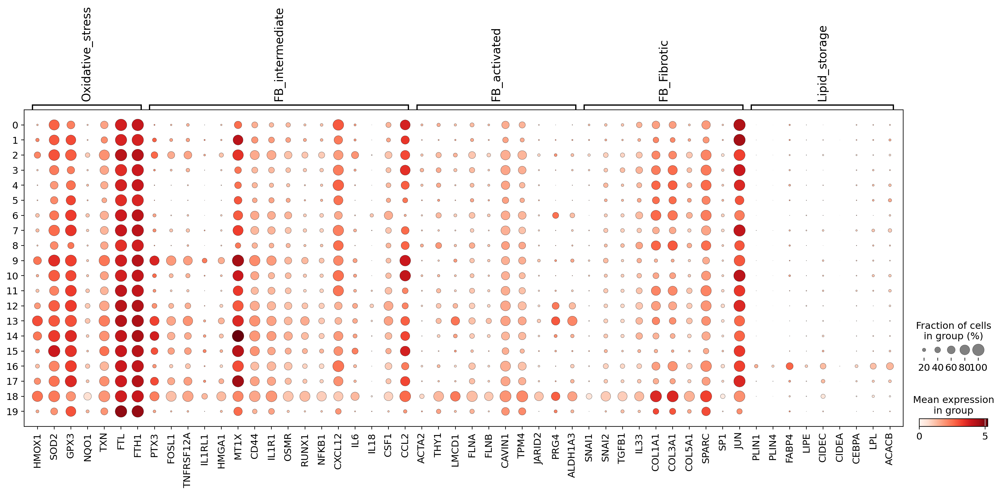

In [28]:
sc.pl.dotplot(adata_fbs_scell, var_names = FB_markers2, groupby = 'Fb-leiden_r1.2', mean_only_expressed=True)

In [36]:
adata_fbs_scell

AnnData object with n_obs × n_vars = 70258 × 26105
    obs: 'sample', 'donor', 'library', 'chemistry_simple', 'chemistry_detail', 'origin_institute', 'study', 'public_data', 'sort', 'sort_type', 'age_group', 'age', 'age_months', 'sex', 'anno_status', 'qc_status', 'taa_l5', 'taa_l4', 'taa_l3', 'taa_l2', 'taa_l1', 'taa_l0', 'n_counts', 'n_genes', 'percent_mito', 'percent_ribo', 'percent_hb', 'scrublet_score', 'Fb-leiden_r0.8', 'Fb-leiden_r1', 'Fb-leiden_r1.2', 'taa_l3_new'
    var: 'gene_ids', 'gene_name', 'n_cells'
    uns: 'neighbors', 'Fb-leiden_r0.8', 'Fb-leiden_r1', 'Fb-leiden_r1.2', 'Fb-leiden_r0.8_colors', 'Fb-leiden_r1_colors', 'Fb-leiden_r1.2_colors', 'taa_l3_new_colors', 'donor_colors'
    obsm: 'X_scVI', 'X_umap'
    obsp: 'distances', 'connectivities'